# Actividad 2.6 — Laboratorio: Implementación de Reglas de Asociación
**IEI097 Minería de Datos · Unidad II · Semana 08** · Trabajo individual
**Estudiante:** Miguel Angel Chura Atora

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/xXElGrisXx/1.9/blob/main/2.6/Actividad_2.6_Reglas_Asociacion_Chura_Miguel.ipynb)

**Objetivo.** Extraer reglas de asociación con el algoritmo **Apriori** (`mlxtend`), comparar configuraciones de umbrales e interpretar las reglas en lenguaje de negocio.

**Fases:** 1 Carga · 2 Preparación · 3 Itemsets frecuentes · 4 Reglas y comparación de umbrales · 5 Interpretación.

## Fase 1 · Carga de datos

**Dataset:** *Groceries Dataset for Market Basket Analysis* (Kaggle, autor `rashikrahmanpritom`).

Las credenciales de Kaggle se leen desde **Colab Secrets** (`KAGGLE_USERNAME` y `KAGGLE_KEY`). Nunca escribas el token dentro del notebook.

In [22]:
!pip -q install mlxtend kagglehub

In [23]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 140)

In [24]:
# Credenciales desde Colab Secrets (no se imprimen)
try:
    from google.colab import userdata
    os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
    os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
    print("Credenciales de Kaggle cargadas desde Colab Secrets.")
except Exception as e:
    print("No se pudieron leer los Secrets:", type(e).__name__)
    print("Revisa que existan KAGGLE_USERNAME y KAGGLE_KEY y que el notebook tenga acceso.")

No se pudieron leer los Secrets: SecretNotFoundError
Revisa que existan KAGGLE_USERNAME y KAGGLE_KEY y que el notebook tenga acceso.


In [25]:
import kagglehub
path = kagglehub.dataset_download("rashikrahmanpritom/groceries-dataset-for-market-basket-analysismba")
csvs = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
print("Archivos del dataset:", [os.path.basename(p) for p in csvs])
# El dataset trae dos archivos: usamos el de transacciones crudas ("Groceries data.csv"), no "basket.csv"
csv_path = next(p for p in csvs if "groceries" in os.path.basename(p).lower())
raw = pd.read_csv(csv_path)
print("Archivo:", os.path.basename(csv_path))
print("Filas x columnas:", raw.shape)
raw.head()

Using Colab cache for faster access to the 'groceries-dataset-for-market-basket-analysismba' dataset.
Archivos del dataset: ['Groceries data.csv', 'basket.csv']
Archivo: Groceries data.csv
Filas x columnas: (38765, 7)


,Member_number,Date,itemDescription,year,month,day,day_of_week
0,1808,2015-07-21,tropical fruit,2015,7,21,1
1,2552,2015-05-01,whole milk,2015,5,1,4
2,2300,2015-09-19,pip fruit,2015,9,19,5
3,1187,2015-12-12,other vegetables,2015,12,12,5
4,3037,2015-01-02,whole milk,2015,1,2,4


### Descripción del dataset

In [26]:
COL_CLIENTE, COL_FECHA, COL_ITEM = "Member_number", "Date", "itemDescription"
faltan = [c for c in (COL_CLIENTE, COL_FECHA, COL_ITEM) if c not in raw.columns]
assert not faltan, f"Columnas esperadas no encontradas: {faltan}. Columnas reales: {list(raw.columns)}"

# Una transacción = un cliente en una fecha (su boleta de ese día)
raw["tx"] = raw[COL_CLIENTE].astype(str) + "|" + raw[COL_FECHA].astype(str)

print("Filas (producto vendido):", len(raw))
print("Transacciones (cliente + fecha):", raw["tx"].nunique())
print("Ítems distintos:", raw[COL_ITEM].nunique())
raw.info()

Filas (producto vendido): 38765
Transacciones (cliente + fecha): 14963
Ítems distintos: 167
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38765 entries, 0 to 38764
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Member_number    38765 non-null  int64 
 1   Date             38765 non-null  object
 2   itemDescription  38765 non-null  object
 3   year             38765 non-null  int64 
 4   month            38765 non-null  int64 
 5   day              38765 non-null  int64 
 6   day_of_week      38765 non-null  int64 
 7   tx               38765 non-null  object
dtypes: int64(5), object(3)
memory usage: 2.4+ MB


**¿Qué es una transacción y qué es un ítem aquí?**
- **Transacción:** la compra de un cliente (`Member_number`) en una fecha (`Date`), es decir, su boleta de ese día.
- **Ítem:** cada producto comprado (`itemDescription`).
- Cada fila del archivo es un producto dentro de una compra, así que hay varias filas por transacción.

*(Contexto en una frase: compras de supermercado de distintos clientes en distintas fechas.)*

## Fase 2 · Preparación de datos

### Revisión de nulos, nombres inconsistentes y filas no válidas

In [27]:
print("Nulos por columna:")
print(raw[["tx", COL_ITEM]].isna().sum())

df = raw.dropna(subset=["tx", COL_ITEM]).copy()

# Normalizar nombres: sin espacios sobrantes y en minúsculas
df["item"] = df[COL_ITEM].astype(str).str.strip().str.lower()

# Filas que no representan productos reales
invalidos = df["item"].isin(["", "nan", "none", "null"])
print("Filas descartadas por no ser productos:", int(invalidos.sum()))
df = df[~invalidos]

# Un mismo ítem repetido dentro de una transacción cuenta una sola vez
antes = len(df)
df = df.drop_duplicates(["tx", "item"])
print("Duplicados dentro de una misma transacción eliminados:", antes - len(df))

# Revisión visual de nombres (busca variantes del mismo producto)
nombres = sorted(df["item"].unique())
print(len(nombres), "ítems distintos tras la limpieza")
print(nombres)

Nulos por columna:
tx                 0
itemDescription    0
dtype: int64
Filas descartadas por no ser productos: 0
Duplicados dentro de una misma transacción eliminados: 759
167 ítems distintos tras la limpieza
['abrasive cleaner', 'artif. sweetener', 'baby cosmetics', 'bags', 'baking powder', 'bathroom cleaner', 'beef', 'berries', 'beverages', 'bottled beer', 'bottled water', 'brandy', 'brown bread', 'butter', 'butter milk', 'cake bar', 'candles', 'candy', 'canned beer', 'canned fish', 'canned fruit', 'canned vegetables', 'cat food', 'cereals', 'chewing gum', 'chicken', 'chocolate', 'chocolate marshmallow', 'citrus fruit', 'cleaner', 'cling film/bags', 'cocoa drinks', 'coffee', 'condensed milk', 'cooking chocolate', 'cookware', 'cream', 'cream cheese', 'curd', 'curd cheese', 'decalcifier', 'dental care', 'dessert', 'detergent', 'dish cleaner', 'dishes', 'dog food', 'domestic eggs', 'female sanitary products', 'finished products', 'fish', 'flour', 'flower (seeds)', 'flower soil/fertil

In [28]:
tamanos = df.groupby("tx")["item"].nunique()
print("Ítems por transacción:")
print(tamanos.describe())
print("Transacciones de un solo ítem:", int((tamanos == 1).sum()))

Ítems por transacción:
count    14963.000000
mean         2.539999
std          1.060993
min          1.000000
25%          2.000000
50%          2.000000
75%          3.000000
max         10.000000
Name: item, dtype: float64
Transacciones de un solo ítem: 205


**Decisión sobre transacciones de un solo ítem:** se mantienen. No generan reglas por sí solas, pero sí cuentan en el total de transacciones, que es el denominador del soporte. Quitarlas inflaría el soporte de todas las reglas.

### Codificación one-hot

In [29]:
transactions = df.groupby("tx")["item"].apply(list).tolist()

te = TransactionEncoder()
basket = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)

print("Tabla codificada (transacciones x ítems):", basket.shape)
basket.iloc[:5, :8]

Tabla codificada (transacciones x ítems): (14963, 167)


,abrasive cleaner,artif. sweetener,baby cosmetics,bags,baking powder,bathroom cleaner,beef,berries
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False


**¿Por qué Apriori necesita este formato?**
`apriori` de `mlxtend` recibe una tabla con **una fila por transacción y una columna por ítem**, con `True/False` según si el ítem está en la compra. Esa matriz binaria permite contar de forma directa y rápida en cuántas transacciones aparece cada combinación de ítems (el soporte). Si se entregaran los datos como una lista de filas producto-por-producto, habría que reconstruir las compras en cada conteo.

## Fase 3 · Itemsets frecuentes

### Distribución de frecuencias (para justificar el soporte mínimo)

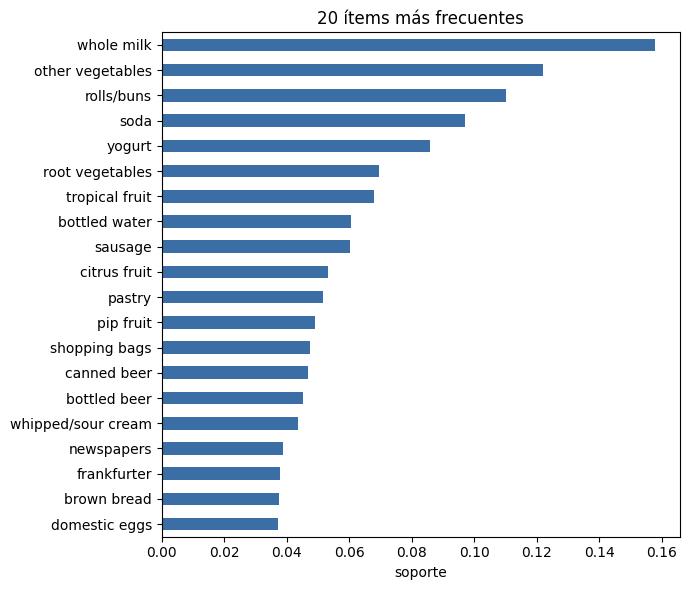

count    167.000000
mean       0.015210
std        0.023381
min        0.000067
25%        0.002038
50%        0.005681
75%        0.017644
max        0.157923
dtype: float64
Ítems con soporte >=   0.1: 3
Ítems con soporte >=  0.05: 11
Ítems con soporte >=  0.02: 38
Ítems con soporte >=  0.01: 64
Ítems con soporte >= 0.005: 89
Ítems con soporte >= 0.002: 126


In [30]:
freq = basket.mean().sort_values(ascending=False)   # soporte de cada ítem

ax = freq.head(20).plot.barh(figsize=(7, 6), color="#3b6ea5")
ax.invert_yaxis(); ax.set_xlabel("soporte"); ax.set_title("20 ítems más frecuentes")
plt.tight_layout(); plt.show()

print(freq.describe())
for s in (0.10, 0.05, 0.02, 0.01, 0.005, 0.002):
    print(f"Ítems con soporte >= {s:>5}: {(freq >= s).sum()}")

**Justificación del soporte mínimo.**
En este dataset las boletas son cortas (en promedio 2,5 ítems por transacción), por eso las combinaciones de dos productos tienen soportes muy bajos. Los ítems más populares son whole milk (15,8 %), other vegetables (12,2 %) y rolls/buns (11,0 %). Cantidad de ítems (de 167) que superan cada soporte: 3 llegan a 10 % o más, 11 a 5 %, 38 a 2 %, 64 a 1 %, 89 a 0,5 % y 126 a 0,2 %.

Con soporte mínimo de 1 % y confianza de 10 % solo salen 4 reglas y todas con lift menor que 1, es decir, ninguna sirve. Por eso elegí **MIN_SUPPORT = 0,002** (unas 30 boletas de las 14.963), que conserva 126 ítems frecuentes y 330 itemsets, una cantidad manejable para Colab. La confianza mínima de **0,05** es baja porque en boletas tan cortas la confianza de casi cualquier regla es pequeña.

In [31]:
MIN_SUPPORT = 0.002   # config C: con soporte 0.01 casi no salen reglas con lift > 1 (ver comparación)
MIN_CONF    = 0.05

itemsets = apriori(basket, min_support=MIN_SUPPORT, use_colnames=True)
itemsets["tamaño"] = itemsets["itemsets"].apply(len)
print("Itemsets frecuentes:", len(itemsets))
print(itemsets["tamaño"].value_counts().sort_index())
itemsets.sort_values("support", ascending=False).head(15)

Itemsets frecuentes: 330
tamaño
1    126
2    204
Name: count, dtype: int64


,support,itemsets,tamaño
123,0.157923,(whole milk),1
77,0.122101,(other vegetables),1
92,0.110005,(rolls/buns),1
103,0.097106,(soda),1
124,0.085879,(yogurt),1
93,0.069572,(root vegetables),1
115,0.067767,(tropical fruit),1
5,0.060683,(bottled water),1
98,0.060349,(sausage),1
22,0.053131,(citrus fruit),1


## Fase 4 · Reglas de asociación

In [32]:
def make_rules(its, n_tx, min_conf):
    # Compatible con distintas versiones de mlxtend
    if len(its) == 0 or (its["itemsets"].apply(len) >= 2).sum() == 0:
        return pd.DataFrame(columns=["antecedents", "consequents", "support", "confidence", "lift"])
    try:
        return association_rules(its, num_itemsets=n_tx, metric="confidence", min_threshold=min_conf)
    except TypeError:
        return association_rules(its, metric="confidence", min_threshold=min_conf)

def pretty(r):
    r = r.copy()
    r["antecedente"] = r["antecedents"].apply(lambda s: ", ".join(sorted(s)))
    r["consecuente"] = r["consequents"].apply(lambda s: ", ".join(sorted(s)))
    return r[["antecedente", "consecuente", "support", "confidence", "lift"]]

rules = make_rules(itemsets, len(basket), MIN_CONF)
print("Reglas generadas:", len(rules))
tabla_reglas = pretty(rules).sort_values("lift", ascending=False).reset_index(drop=True)
tabla_reglas.head(20)

Reglas generadas: 219


,antecedente,consecuente,support,confidence,lift
0,curd,sausage,0.002941,0.087302,1.446615
1,canned beer,brown bread,0.002406,0.051282,1.362937
2,brown bread,canned beer,0.002406,0.063943,1.362937
3,frozen vegetables,sausage,0.002072,0.073986,1.225966
4,sausage,bottled beer,0.003342,0.055371,1.222000
5,bottled beer,sausage,0.003342,0.073746,1.222000
6,frankfurter,other vegetables,0.005146,0.136283,1.116150
7,sausage,yogurt,0.005748,0.095238,1.108986
8,yogurt,sausage,0.005748,0.066926,1.108986
9,frozen vegetables,root vegetables,0.002139,0.076372,1.097751


**Criterio de orden:** se ordenan por **lift**, porque el lift (confianza de la regla ÷ soporte del consecuente) indica si la asociación es mayor que lo esperable por azar. Un lift cercano a 1 significa que X e Y aparecen juntos tanto como se esperaría si fueran independientes; un lift mayor que 1 indica una asociación real. Ordenar solo por confianza favorecería reglas cuyo consecuente es un producto muy popular.

### Experimento obligatorio: tres configuraciones de umbrales

In [33]:
configs = [
    ("A (estricta)",  0.010, 0.10),
    ("B (intermedia)", 0.005, 0.10),
    ("C (laxa)",       0.002, 0.05),
]
filas = []
for nombre, s, c in configs:
    its = apriori(basket, min_support=s, use_colnames=True)
    rl = make_rules(its, len(basket), c)
    filas.append({
        "configuración": nombre,
        "soporte mínimo": s,
        "confianza mínima": c,
        "itemsets frecuentes": len(its),
        "reglas": len(rl),
        "lift máximo": round(rl["lift"].max(), 2) if len(rl) else np.nan,
    })
comparacion = pd.DataFrame(filas)
comparacion

,configuración,soporte mínimo,confianza mínima,itemsets frecuentes,reglas,lift máximo
0,A (estricta),0.010,0.10,69,4,0.82
1,B (intermedia),0.005,0.10,126,19,1.12
2,C (laxa),0.002,0.05,330,219,1.45


**Conclusión de la comparación.**

| Configuración | Soporte mínimo | Confianza mínima | Itemsets | Reglas | Lift máximo |
|---|---|---|---|---|---|
| A (estricta) | 0,010 | 0,10 | 69 | 4 | 0,82 |
| B (intermedia) | 0,005 | 0,10 | 126 | 19 | 1,12 |
| C (laxa) | 0,002 | 0,05 | 330 | 219 | 1,45 |

Al bajar el soporte y la confianza, los itemsets pasan de 69 a 330 y las reglas de 4 a 219, es decir, aparecen muchas más reglas. En la configuración A todas las reglas tienen lift menor que 1 (los productos se compran juntos menos de lo esperable), y en la B solo una regla supera apenas 1. Solo la C entrega reglas con lift claramente mayor que 1 (24 reglas con lift mayor que 1 y 6 con lift mayor que 1,2). Elijo la **configuración C** para el análisis, porque es la única que permite encontrar asociaciones reales. El costo es que cada regla se apoya en pocas boletas (cerca de 30), por lo que hay que interpretarlas con cuidado.

### Verificación manual de una regla (como en la Actividad 2.5)

In [34]:
def contar(antecedente, consecuente, trans):
    A, Cc = set(antecedente), set(consecuente)
    n = len(trans)
    nA  = sum(A <= set(t) for t in trans)
    nAC = sum((A | Cc) <= set(t) for t in trans)
    return {"transacciones": n, "con X": nA, "con X e Y": nAC,
            "soporte": round(nAC / n, 4), "confianza": round(nAC / nA, 4) if nA else np.nan}

if len(rules):
    fila = rules.sort_values("lift", ascending=False).iloc[0]
    X, Y = set(fila["antecedents"]), set(fila["consequents"])
    print("Regla:", sorted(X), "=>", sorted(Y))
    print("mlxtend  -> soporte:", round(fila["support"], 4), "| confianza:", round(fila["confidence"], 4), "| lift:", round(fila["lift"], 3))
    print("Conteo a mano sobre TODAS las transacciones:", contar(X, Y, transactions))
    print("Conteo a mano sobre una muestra de 200:     ", contar(X, Y, transactions[:200]))

Regla: ['curd'] => ['sausage']
mlxtend  -> soporte: 0.0029 | confianza: 0.0873 | lift: 1.447
Conteo a mano sobre TODAS las transacciones: {'transacciones': 14963, 'con X': 504, 'con X e Y': 44, 'soporte': 0.0029, 'confianza': 0.0873}
Conteo a mano sobre una muestra de 200:      {'transacciones': 200, 'con X': 6, 'con X e Y': 0, 'soporte': 0.0, 'confianza': 0.0}


Si el conteo manual sobre todas las transacciones coincide con `mlxtend`, la preparación de los datos es correcta. El conteo sobre la muestra solo ilustra el procedimiento de la Actividad 2.5.

## Fase 5 · Interpretación

In [35]:
# Candidatas: reglas con mayor lift y soporte razonable
candidatas = tabla_reglas[tabla_reglas["support"] >= MIN_SUPPORT].head(15)
candidatas

,antecedente,consecuente,support,confidence,lift
0,curd,sausage,0.002941,0.087302,1.446615
1,canned beer,brown bread,0.002406,0.051282,1.362937
2,brown bread,canned beer,0.002406,0.063943,1.362937
3,frozen vegetables,sausage,0.002072,0.073986,1.225966
4,sausage,bottled beer,0.003342,0.055371,1.222000
5,bottled beer,sausage,0.003342,0.073746,1.222000
6,frankfurter,other vegetables,0.005146,0.136283,1.116150
7,sausage,yogurt,0.005748,0.095238,1.108986
8,yogurt,sausage,0.005748,0.066926,1.108986
9,frozen vegetables,root vegetables,0.002139,0.076372,1.097751


In [36]:
# Posibles reglas a descartar: superan los umbrales pero tienen lift cercano a 1 (casi sin asociación real)
descarte = tabla_reglas[(tabla_reglas["lift"] < 1.15)].sort_values("support", ascending=False).head(10)
descarte

,antecedente,consecuente,support,confidence,lift
159,other vegetables,whole milk,0.014837,0.121511,0.769430
160,whole milk,other vegetables,0.014837,0.093948,0.769430
124,whole milk,rolls/buns,0.013968,0.088447,0.804028
123,rolls/buns,whole milk,0.013968,0.126974,0.804028
169,soda,whole milk,0.011629,0.119752,0.758296
168,whole milk,soda,0.011629,0.073635,0.758296
100,whole milk,yogurt,0.011161,0.070673,0.822940
99,yogurt,whole milk,0.011161,0.129961,0.822940
139,rolls/buns,other vegetables,0.010559,0.095990,0.786154
138,other vegetables,rolls/buns,0.010559,0.086481,0.786154


### Las 5 reglas más valiosas (lenguaje de negocio)
Se eligieron de la configuración C, ordenadas por lift. Para leerlas: "de cada 100 compras con X, unas N incluyen también Y, frente a M en una compra cualquiera".

| # | Regla | Soporte | Confianza | Lift | Qué significa para el negocio |
|---|---|---|---|---|---|
| 1 | curd => sausage | 0,29 % | 8,7 % | 1,45 | De cada 100 compras con requesón, unas 9 llevan también salchichas, frente a 6 en una compra cualquiera. Es la asociación más fuerte encontrada. |
| 2 | brown bread => canned beer | 0,24 % | 6,4 % | 1,36 | De cada 100 compras con pan integral, unas 6 llevan cerveza en lata, frente a unas 5 en una compra cualquiera. |
| 3 | bottled beer => sausage | 0,33 % | 7,4 % | 1,22 | De cada 100 compras con cerveza embotellada, unas 7 llevan salchichas, frente a 6 en una compra cualquiera. |
| 4 | frozen vegetables => sausage | 0,21 % | 7,4 % | 1,23 | De cada 100 compras con verduras congeladas, unas 7 llevan salchichas, frente a 6 en una compra cualquiera. |
| 5 | frankfurter => other vegetables | 0,51 % | 13,6 % | 1,12 | De cada 100 compras con vienesas, unas 14 llevan otras verduras, frente a 12 en una compra cualquiera. Es la regla con más respaldo, porque ocurre en más boletas. |

### Regla que descartaría
**other vegetables => whole milk**, con soporte 1,48 %, confianza 12,2 % y lift 0,77. Supera los umbrales (soporte mínimo 0,2 % y confianza mínima 5 %) y es de las reglas más frecuentes, pero su lift es menor que 1: entre quienes compran otras verduras, el 12,2 % lleva leche entera, menos que el 15,8 % del total de boletas. Su soporte y su confianza altos solo reflejan que la leche entera es el producto más popular, no que exista una asociación. Poner estos productos juntos no aumentaría las ventas.

### Decisión concreta para un administrador
Ubicar cerca salchichas, vienesas y cerveza (embotellada y en lata) y ofrecer una promoción cruzada, por ejemplo un descuento en cerveza al llevar salchichas. También exhibir las verduras congeladas junto a las salchichas. No gastar espacio ni promociones en juntar leche entera con otras verduras. Como las asociaciones son débiles (confianza máxima cercana a 14 % y lift máximo de 1,45), conviene probar primero con una promoción piloto de pocas semanas y medir si suben las ventas, antes de reordenar toda la tienda.

### Reflexión final (máximo 6 líneas)
Aprendí que soporte y confianza no bastan: hay que mirar el lift para saber si la asociación es real, como en la regla de leche con verduras, que parece fuerte y no lo es. En este dataset las boletas son cortas (2,5 ítems en promedio), por eso las reglas son débiles y hubo que bajar mucho los umbrales. Bajarlos entrega más reglas, pero apoyadas en pocas boletas y con más riesgo de ruido. Lo que a mano costaba con 8 transacciones, Apriori lo hace en segundos con casi 15.000, pero decidir los umbrales e interpretar las reglas sigue siendo trabajo de una persona. Las reglas describen co-ocurrencia, no causa ni predicción.